# Limpieza y preprocesamiento de datos

## Ingesta

In [2]:
# Recuperación de contenido del archivo CSV y creación de un DataFrame de pandas
import pandas as pd

# Cargar el archivo CSV en un DataFrame
df = pd.read_csv('retail_x_clientes.csv')
df

,customer_id,edad,ingresos,ciudad,fecha_ultima_compra,num_compras,deuda,churn
0,1860,50,23962.22,Ciudad de México,2023-08-30,4,5365.92,1.0
1,4772,49,NaN,puebla,2023-06-05,5,4692.15,1.0
2,4092,17,NaN,CDMX,2022-11-29,9,4617.36,1.0
3,1466,40,NaN,Puebla,2021-10-09,5,2101.78,0.0
4,5426,21,9998.37,Ciudad de México,2023-09-02,3,-1798.42,0.0
...,...,...,...,...,...,...,...,...
9995,5931,43,14059.39,CDMX,2021-07-31,6,2035.49,0.0
9996,2691,31,9851.20,CDMX,2022-01-17,4,4674.32,1.0
9997,5550,15,17832.33,México D.F.,2021-02-10,1,6148.24,1.0
9998,5408,44,13644.92,Puebla,2021-10-30,2,3710.74,1.0


## Identificación de características generales del conjunto de datos

En esta fase, se realiza una inspección general de la estructura del conjunto de datos con el objetivo de identificar características generales con número de items, tipos de datos, datos nulos, items etiquetados/ no etiquetados, entre otras.

In [3]:
# Recuperando una muestra de los datos para inspección
df.head()

,customer_id,edad,ingresos,ciudad,fecha_ultima_compra,num_compras,deuda,churn
0,1860,50,23962.22,Ciudad de México,2023-08-30,4,5365.92,1.0
1,4772,49,NaN,puebla,2023-06-05,5,4692.15,1.0
2,4092,17,NaN,CDMX,2022-11-29,9,4617.36,1.0
3,1466,40,NaN,Puebla,2021-10-09,5,2101.78,0.0
4,5426,21,9998.37,Ciudad de México,2023-09-02,3,-1798.42,0.0


In [4]:
df.tail()

,customer_id,edad,ingresos,ciudad,fecha_ultima_compra,num_compras,deuda,churn
9995,5931,43,14059.39,CDMX,2021-07-31,6,2035.49,0.0
9996,2691,31,9851.20,CDMX,2022-01-17,4,4674.32,1.0
9997,5550,15,17832.33,México D.F.,2021-02-10,1,6148.24,1.0
9998,5408,44,13644.92,Puebla,2021-10-30,2,3710.74,1.0
9999,1227,42,NaN,Puebla,2024-02-24,6,2112.72,1.0


In [5]:
# Visualización de información general del DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          10000 non-null  int64  
 1   edad                 10000 non-null  int64  
 2   ingresos             7000 non-null   float64
 3   ciudad               10000 non-null  str    
 4   fecha_ultima_compra  10000 non-null  str    
 5   num_compras          10000 non-null  int64  
 6   deuda                10000 non-null  float64
 7   churn                8999 non-null   float64
dtypes: float64(3), int64(3), str(2)
memory usage: 625.1 KB


Derivado de la observación que se ha realizado a través de las muestras proporcionadas por .head() y por .tail(), además de la la tarjeta informativa del dataframe se han realizado los siguientes hallazgos:
- En el caso de *ciudad* algunas denominaciones hacen referencia a la misma ubicación, específicamente: CDMX, Ciudad de México, México D.F.
- En el caso de *fecha_ultima_compra* se ha identificado que el tipo de dato es cadena y no *date*, esto afecta el filtrado del contenido a través de marcas de tiempo.
- Con respecto a *ingresos* y *churn* se puede observar que hay un faltante de datos de 3000 y 1001 datos respectivamente.

## Tratamiento de los datos duplicados

In [6]:
# Identificación de los valores duplicados en el DataFrame
df[df.duplicated(subset=['customer_id'])].count()

customer_id            5719
edad                   5719
ingresos               3963
ciudad                 5719
fecha_ultima_compra    5719
num_compras            5719
deuda                  5719
churn                  5132
dtype: int64

In [7]:
# Identificando registros duplicados de customer_id y mostrando los registros duplicados
df.duplicated(subset=['customer_id']).sum()

np.int64(5719)

In [8]:
# Listado de los registros duplicados de customer_id
df[df.duplicated(subset=['customer_id'], keep=False)].sort_values(by='customer_id')

,customer_id,edad,ingresos,ciudad,fecha_ultima_compra,num_compras,deuda,churn
1686,1001,15,NaN,México D.F.,2023-02-12,5,6127.48,1.0
5933,1001,50,13251.88,puebla,2023-02-11,4,4224.34,0.0
1572,1001,32,14210.64,Puebla,2023-03-04,7,7655.77,1.0
8525,1002,38,NaN,México D.F.,2023-10-26,4,5875.85,1.0
4064,1002,51,NaN,Ciudad de México,2022-07-09,5,3550.15,1.0
...,...,...,...,...,...,...,...,...
9515,5995,48,13483.33,Puebla,2023-10-17,4,5553.79,0.0
6337,5995,52,10196.82,Ciudad de México,2021-08-16,6,4217.40,1.0
9667,5995,34,NaN,CDMX,2023-09-23,5,4192.25,1.0
8991,5997,26,16262.02,Ciudad de México,2022-02-04,5,5098.87,0.0


## Tratamiento de los datos faltantes

Los datos faltantes ocurren o se identifican cuando por alguna razón, éstos no se registran en una o mas ocasiones. Algunos mecanismos de pérdida  de los datos pueden ser:
- MCAR (*Missing Completely ar Random*): Cuando la causa de la ausencia no esta relacionada con ninguna otra variable.
- MAR (*Missing at Random*): Cuando la ausencia del dato depende de otras variables (datos derivados).
- MNAR (*Missing not at Random*): Cuando la ausencia del datos depende directamente de otro valor faltante.

### Criterios para la selección de un método de imputación

Al proceso de sustitución de los datos nulos dentro de un conjunto de datos se le denomina *imputación* y los criterios que se pueden seguir para realizar esto son:
- Basado en el porcentaje de datos nulos
    - Si es menor que 5% entonces se pueden considerar métricas de tendencia central o incluso, la eliminación de los registros.
    - Si se considera la imputación por Media o Mediana:
        - Media en el caso de que la variable se simétrica y gaussiana (no tenga valores atípicos).
        - Mediana que es resistente a los valores atípicos
- Basado en condicionales o modelos
    - Si el porcentaje es mayor al 5% pero menor al 10%
        - Condicionales: Asignar una media de tendencia central basada en grupos
        - Modelos: Este criterio esta basado en algoritmos de aprendizaje automático (ML) tales como KNN (Vecinos mas cercanos).
    - Si el porcentaje es mayor al 10%, se pueden ocupar los metodos anteriores o la eliminación de los mismos.

In [10]:
# Conteo de valores nulos y su porcentaje en cada columna del DataFrame
nulos = pd.DataFrame({
    'Nulos_absolutos': df.isna().sum(),
    'Porcentaje_%': (df.isna().mean() * 100).round(2)
})
print("--- Distribución de los valores nulos ---")
print(nulos)

--- Distribución de los valores nulos ---
                     Nulos_absolutos  Porcentaje_%
customer_id                        0          0.00
edad                               0          0.00
ingresos                        3000         30.00
ciudad                             0          0.00
fecha_ultima_compra                0          0.00
num_compras                        0          0.00
deuda                              0          0.00
churn                           1001         10.01


In [ ]:
# Identificación de los valores nulos de Ingresos con respecto a la Ciudad
nulos_ingresos_ciudad = df[df['ingresos'].isna()]['ciudad'].value_counts()
print("--- Distribución de los valores nulos de Ingresos por Ciudad ---")
print(nulos_deuda_ciudad)

--- Distribución de los valores nulos de Ingresos por Ciudad ---
ciudad
Puebla              616
Ciudad de México    571
CDMX                563
puebla              489
México D.F.         436
Guadalajara         325
Name: count, dtype: int64


In [ ]:
# Identificación de los valores nulos de Ingresos con respecto a la Edad
nulos_deuda_edad = df[df['ingresos'].isna()]['edad'].value_counts()
print("--- Distribución de los valores nulos de Ingresos por Edad ---")
print(nulos_deuda_edad)

--- Distribución de los valores nulos de Ingresos por Edad ---
edad
40    112
38    106
42    106
39    103
35     91
     ... 
75      1
79      1
74      1
9       1
0       1
Name: count, Length: 81, dtype: int64


In [ ]:
# Evaluación del coeficiente de asimetría (skewness) de la variable 'ingresos' y 'deuda'
skewness_deuda = df['ingresos'].skew()
skewness_deuda = df['deuda'].skew()
print(f"Coeficiente de asimetría (skewness) de la variable 'ingresos': {skewness_ingresos}")
print(f"Coeficiente de asimetría (skewness) de la variable 'deuda': {skewness_deuda}")

Coeficiente de asimetría (skewness) de la variable 'ingresos': 0.030940549152242112
Coeficiente de asimetría (skewness) de la variable 'deuda': 8.765197341722475


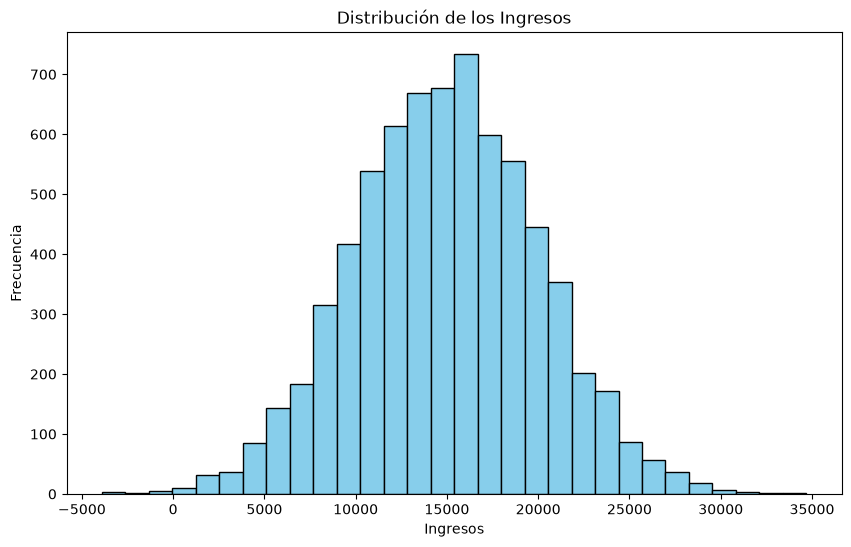

In [14]:
# Grafica de distribución de los ingresos
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(df['ingresos'], bins=30, color='skyblue', edgecolor='black')
plt.title('Distribución de los Ingresos')
plt.xlabel('Ingresos')
plt.ylabel('Frecuencia')
plt.show()


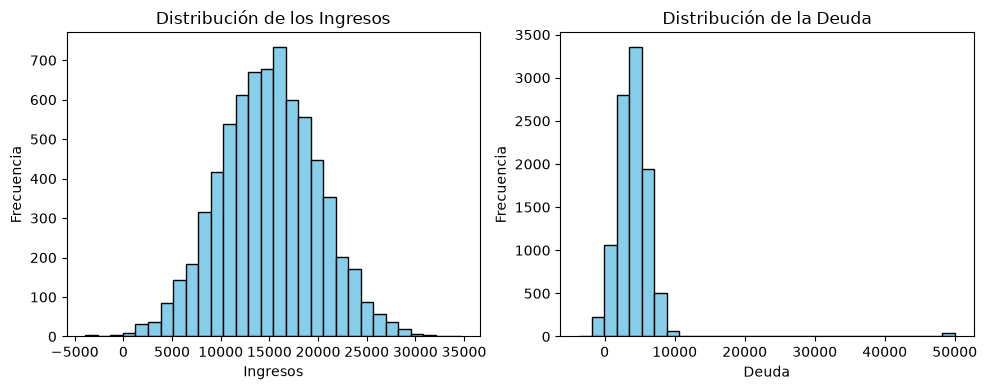

In [17]:
# Grafica de distribución de los ingresos (subplot-1) y la deuda (subplot-2) 
plt.figure(figsize=(10, 4))
# Subplot 1: Distribución de los ingresos
plt.subplot(1, 2, 1)
plt.hist(df['ingresos'], bins=30, color='skyblue', edgecolor='black')
plt.title('Distribución de los Ingresos')
plt.xlabel('Ingresos')
plt.ylabel('Frecuencia')

# Subplot 2: Distribución de la deuda
plt.subplot(1, 2, 2)
plt.hist(df['deuda'], bins=30, color='skyblue', edgecolor='black')
plt.title('Distribución de la Deuda')
plt.xlabel('Deuda')
plt.ylabel('Frecuencia')

plt.tight_layout()
plt.show()

In [18]:
# Diagnostico de los datos atípicos (outliers) mediante el método de Rango Intercuartílico (IQR)

# 1. Con respecto a los Ingresos
Q1_ingresos = df['ingresos'].quantile(0.25)
Q3_ingresos = df['ingresos'].quantile(0.75)
IQR_ingresos = Q3_ingresos - Q1_ingresos

LI_ingresos = Q1_ingresos - 1.5 * IQR_ingresos
LS_ingresos = Q3_ingresos + 1.5 * IQR_ingresos

outliers_ingresos = ((df['ingresos'] < LI_ingresos) | (df['ingresos']>LS_ingresos)).sum()
print(f"[Ingresos] Q1={Q1_ingresos:.2f}, Q3={Q3_ingresos:.2f}, IQR={IQR_ingresos:.2f}")
print(f"[Ingresos] Limite inferior(LI)={LI_ingresos:.2f}, Limite superior (LS)={LS_ingresos:.2f} ")
print(f"[Ingresos] Datos atípicos= {outliers_ingresos}")


[Ingresos] Q1=11479.54, Q3=18393.65, IQR=6914.10
[Ingresos] Limite inferior(LI)=1108.39, Limite superior (LS)=28764.80 
[Ingresos] Datos atípicos= 41


In [19]:
# 2. Con respecto a la Deuda
Q1_deuda = df['deuda'].quantile(0.25)
Q3_deuda = df['deuda'].quantile(0.75)
IQR_deuda = Q3_deuda - Q1_deuda

LI_deuda = Q1_deuda - 1.5 * IQR_deuda
LS_deuda = Q3_deuda + 1.5 * IQR_deuda

outliers_deuda = ((df['deuda'] < LI_deuda) | (df['deuda']>LS_deuda)).sum()
print(f"[deuda] Q1={Q1_deuda:.2f}, Q3={Q3_deuda:.2f}, IQR={IQR_deuda:.2f}")
print(f"[deuda] Limite inferior(LI)={LI_deuda:.2f}, Limite superior (LS)={LS_deuda:.2f} ")
print(f"[deuda] Datos atípicos= {outliers_deuda}")

[deuda] Q1=2622.23, Q3=5333.20, IQR=2710.97
[deuda] Limite inferior(LI)=-1444.23, Limite superior (LS)=9399.65 
[deuda] Datos atípicos= 102
